In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import modeling packages/libraries
from xgboost import XGBClassifier, plot_importance

# Import modeling and metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

import pickle

In [2]:
# Importing the dataset using pandas
df0 = pd.read_csv('HR_capstone_dataset.csv')

# Display first 10 rows of the dataset
df0.head(10)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
5,0.41,0.50,2,153,3,0,1,0,sales,low
6,0.10,0.77,6,247,4,0,1,0,sales,low
7,0.92,0.85,5,259,5,0,1,0,sales,low
8,0.89,1.00,5,224,5,0,1,0,sales,low
9,0.42,0.53,2,142,3,0,1,0,sales,low


In [3]:
# Understanding the Dataset
# Gathering basic information about the data
# pd.shape; pd.info()

print(df0.shape)
df0.info()

(14999, 10)
<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [4]:
# Gathering descriptive statistics
df0.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [5]:
# Display column names
print(df0.columns)
print()

# Standardize columns
df0.columns = (
    df0.columns.str.strip().str.lower()
)
df0 = df0.rename({'average_montly_hours':'average_monthly_hours'}, axis=1)

# Validate changes
print(df0.columns)


Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='str')

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_monthly_hours', 'time_spend_company', 'work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')


In [6]:
# Checking missing values
df0.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_monthly_hours    0
time_spend_company       0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

In [7]:
# Checking duplicated entries
print(f"Total duplicated entries: {df0.duplicated().sum()}")

# Inspecting duplicates
df0[df0.duplicated(keep=False)].sort_values(by=list(df0.columns), ascending=False)

Total duplicated entries: 3008


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,work_accident,left,promotion_last_5years,department,salary
10691,1.00,0.93,5,231,2,0,0,0,marketing,medium
12902,1.00,0.93,5,231,2,0,0,0,marketing,medium
11375,1.00,0.93,5,167,3,0,0,0,sales,medium
13586,1.00,0.93,5,167,3,0,0,0,sales,medium
10878,1.00,0.88,6,201,4,0,0,0,technical,low
...,...,...,...,...,...,...,...,...,...,...
12071,0.09,0.77,5,275,4,0,1,0,product_mng,medium
14282,0.09,0.77,5,275,4,0,1,0,product_mng,medium
30,0.09,0.62,6,294,4,0,1,0,accounting,low
12030,0.09,0.62,6,294,4,0,1,0,accounting,low


In [8]:
# Dropping duplicates
# Save in new variable
df1 = df0.drop_duplicates()

# Validate entries/records
df1.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


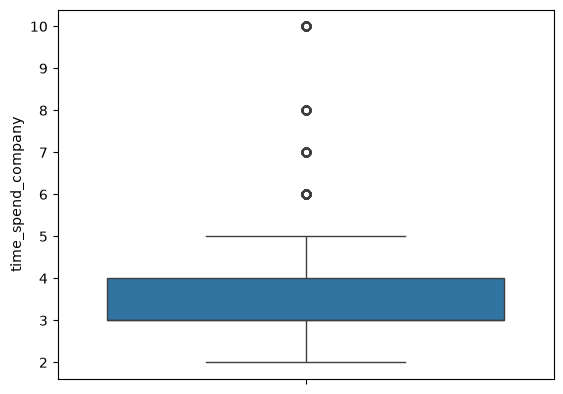

In [9]:
# Create a boxplot: time_spend_company
p = sns.boxplot(
    df1.time_spend_company
)

In [10]:
# Determine total entries with time_spend_company outliers
df1[df1.time_spend_company > 5].count()

satisfaction_level       824
last_evaluation          824
number_project           824
average_monthly_hours    824
time_spend_company       824
work_accident            824
left                     824
promotion_last_5years    824
department               824
salary                   824
dtype: int64

In [11]:
# Checking class imbalance
cnt = df1['left'].value_counts()
print(f'Employee counts:\n{cnt}')

left = cnt[1]/sum(cnt)
stayed = cnt[0]/sum(cnt)

print(f'\nEmployee count percentage:\nChurned:\t{left*100:.2f}\nRetained:\t{stayed*100:.2f}')

Employee counts:
left
0    10000
1     1991
Name: count, dtype: int64

Employee count percentage:
Churned:	16.60
Retained:	83.40


## Data Visualizations

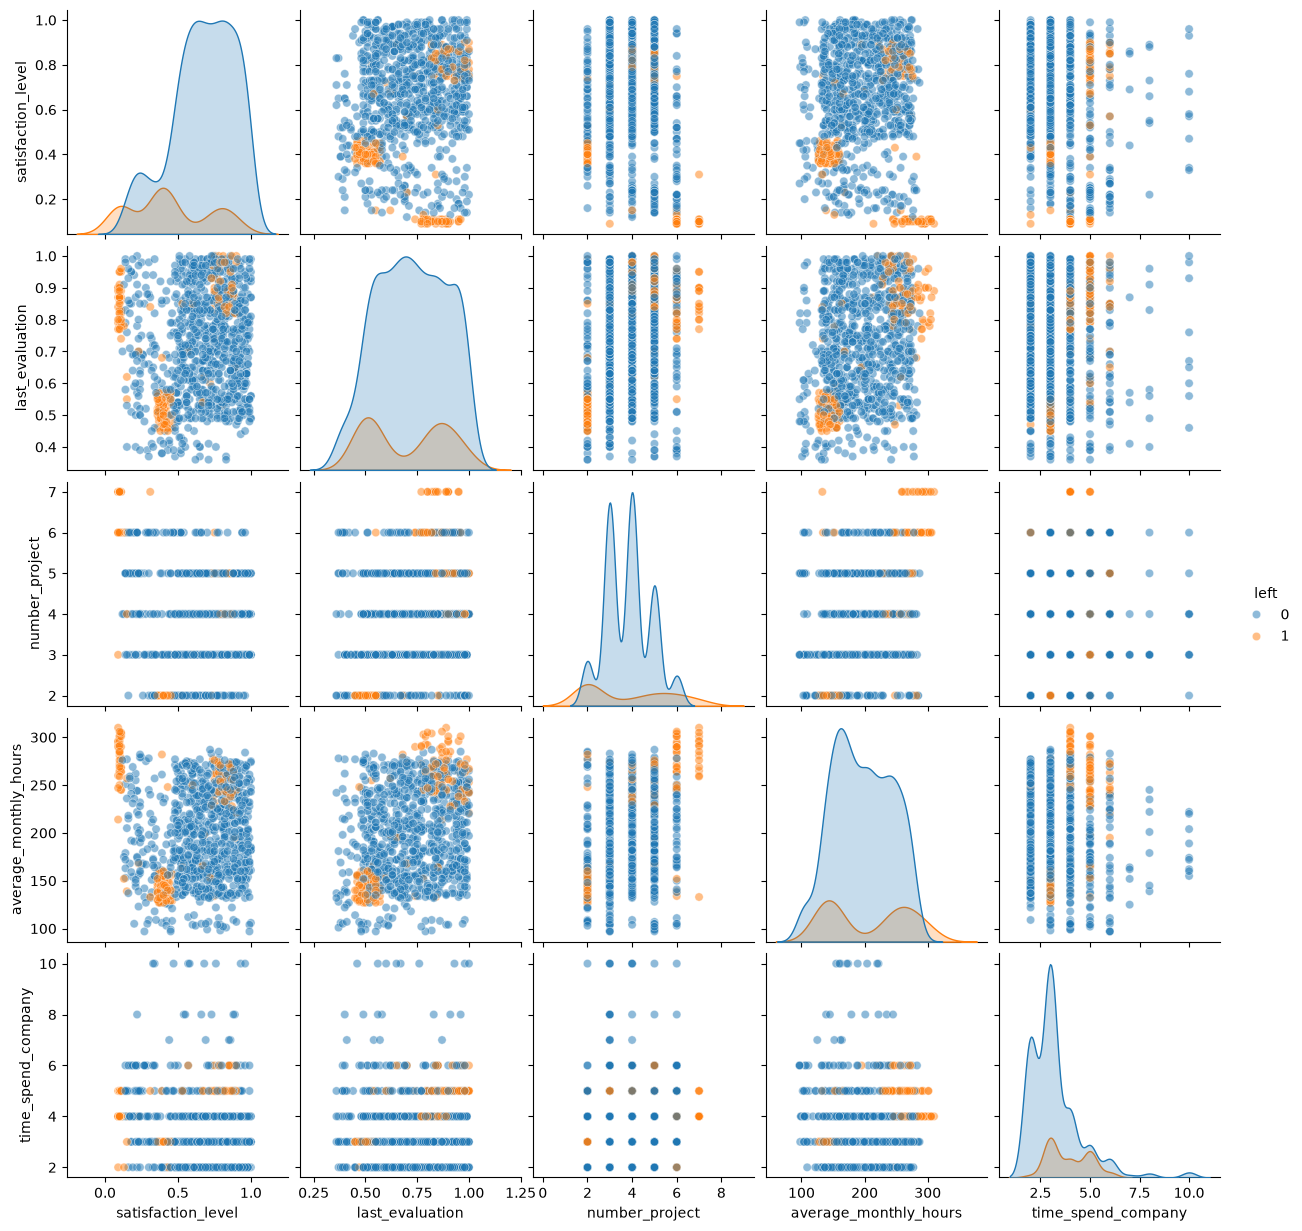

In [12]:
# Visualize all variables
sample_df = df1[df1.columns[:7]].drop(df1.columns[5], axis=1).sample(1000, random_state=42)
sns.pairplot(
    sample_df,
    hue='left',
    plot_kws={'alpha':0.5}
)

<Axes: xlabel='last_evaluation', ylabel='satisfaction_level'>

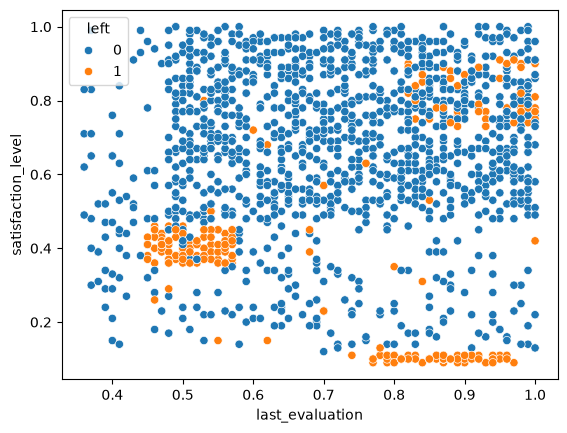

In [13]:
sns.scatterplot(
    y='satisfaction_level',
    x='last_evaluation',
    data=df1.sample(1500, random_state=42),
    hue='left'
)

<Axes: xlabel='average_monthly_hours', ylabel='satisfaction_level'>

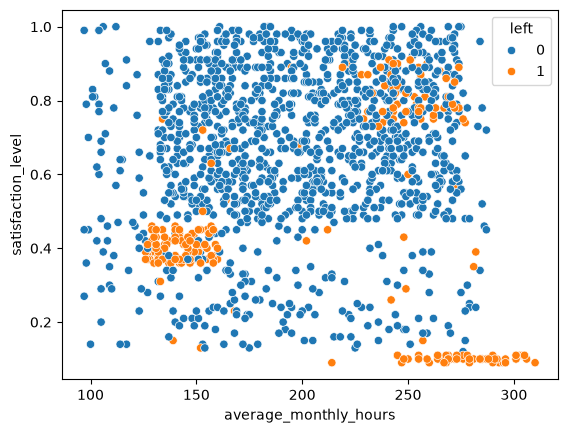

In [14]:
sns.scatterplot(
    y='satisfaction_level',
    x='average_monthly_hours',
    data=df1.sample(1500, random_state=42),
    hue='left'
)

<Axes: xlabel='average_monthly_hours', ylabel='last_evaluation'>

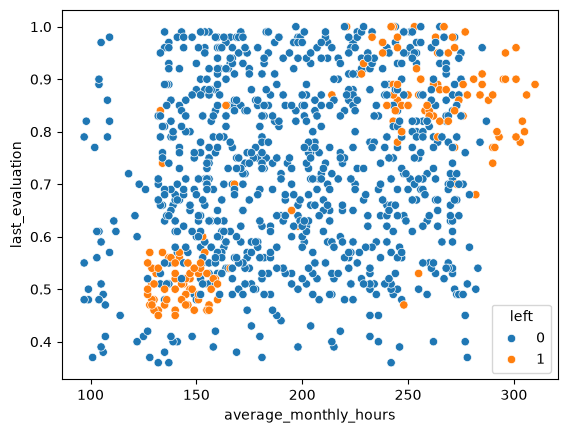

In [15]:
sns.scatterplot(
    x='average_monthly_hours',
    y='last_evaluation',
    data=df1.sample(1000,random_state=42),
    hue='left'
)

<Axes: xlabel='time_spend_company', ylabel='number_project'>

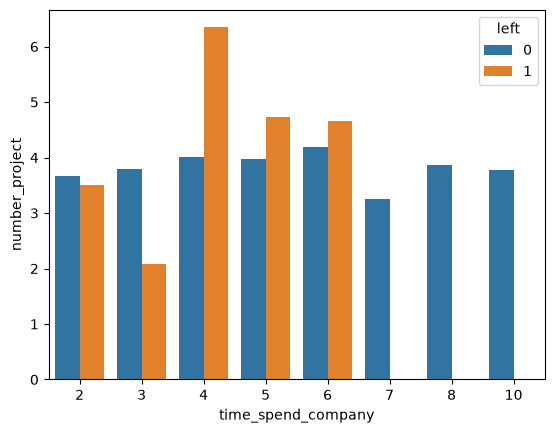

In [16]:
sns.barplot(
    x='time_spend_company',
    y='number_project',
    data=df1.sample(1000, random_state=42),
    hue='left',
    errorbar=None
)

<Axes: xlabel='satisfaction_level', ylabel='left'>

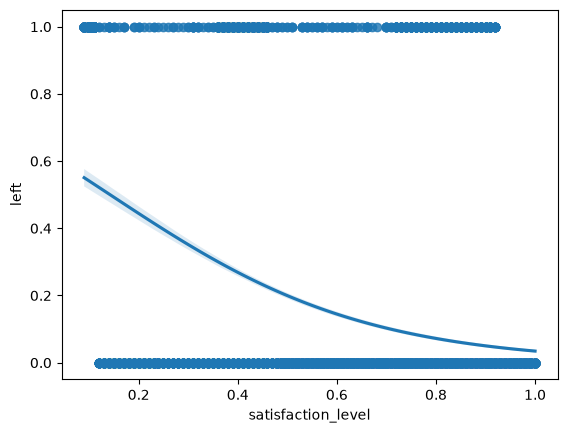

In [17]:
sns.regplot(
    x = 'satisfaction_level',
    y = 'left',
    data = df1,
    logistic=True
)

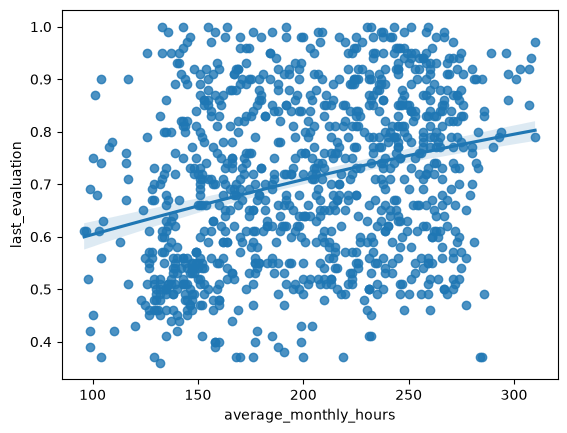

In [18]:
sns.regplot(
    x = 'average_monthly_hours',
    y = 'last_evaluation',
    data = df1.sample(1000, random_state=0),
    logistic=True
)
plt.show()

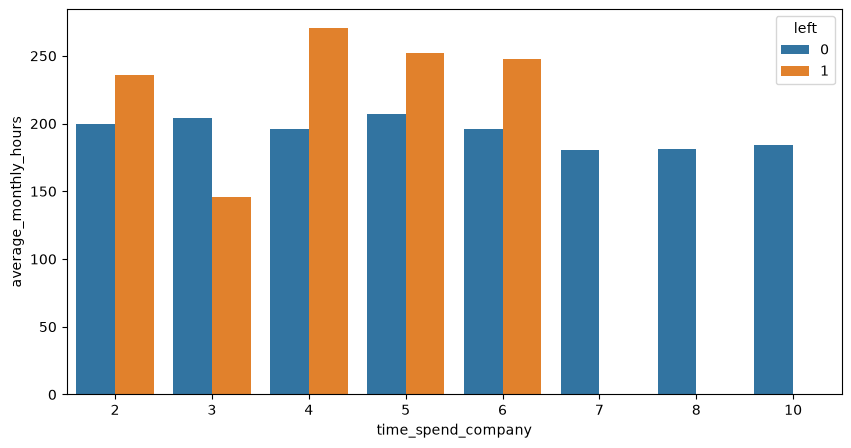

In [19]:
fig, ax = plt.subplots(figsize=(10,5))
p = sns.barplot(
    y = 'average_monthly_hours',
    x = 'time_spend_company',
    data = df1.sample(1000, random_state=0),
    hue='left',
    ax=ax,
    errorbar=None
)
plt.show()

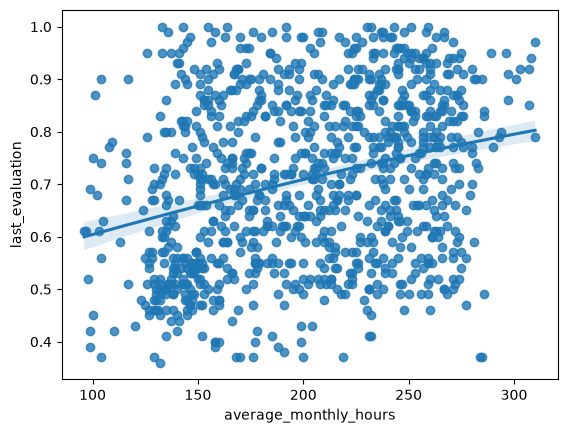

In [20]:
sns.regplot(
    y = 'last_evaluation',
    x = 'average_monthly_hours',
    data = df1.sample(1000, random_state=0),
    logistic=True
)
plt.show()

In [21]:
# df1.info()
# Drop unrelated and contradicting variables

df2 = df1.copy()
df2 = df2.drop(['satisfaction_level','work_accident','promotion_last_5years'], axis=1)

# df2.info()

# transform department and salary to binary variables
df2 = pd.get_dummies(df2, dtype=int, drop_first=True)
df2.head()

,last_evaluation,number_project,average_monthly_hours,time_spend_company,left,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical,salary_low,salary_medium
0,0.53,2,157,3,1,0,0,0,0,0,0,1,0,0,1,0
1,0.86,5,262,6,1,0,0,0,0,0,0,1,0,0,0,1
2,0.88,7,272,4,1,0,0,0,0,0,0,1,0,0,0,1
3,0.87,5,223,5,1,0,0,0,0,0,0,1,0,0,1,0
4,0.52,2,159,3,1,0,0,0,0,0,0,1,0,0,1,0


In [22]:
# Set X,y variable
# Split the data
X = df2.drop(['left'],axis=1)
y = df2['left']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

In [23]:
xgb = XGBClassifier(objective='binary:logistic', random_state=0)

cv_xgb_params = {
    'learning_rate':[0.1],
    'max_depth':[6,5,4,3],
    'min_child_weight':[3,5,7],
    'n_estimators':[250,500,750]
}

scoring = {
    'precision':'precision',
    'recall':'recall',
    'f1':'f1',
    'accuracy':'accuracy'
}

xgb_cv = GridSearchCV(
    xgb,
    cv_xgb_params,
    scoring=scoring,
    cv=5,
    refit='f1'
)

In [24]:
xgb_cv.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1], 'max_depth': [6, 5, ...], 'min_child_weight': [3, 5, ...], 'n_estimators': [250, 500, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... 

In [25]:
xgb_cv.best_params_

def make_results(model_name:str, model_fit):

    rf_cv_results = pd.DataFrame(model_fit.cv_results_)
    best_estimator_results = rf_cv_results.iloc[rf_cv_results['mean_test_f1'].idxmax(),:]

    accuracy = best_estimator_results.mean_test_accuracy
    precision = best_estimator_results.mean_test_precision
    recall = best_estimator_results.mean_test_recall
    f1 = best_estimator_results.mean_test_f1

    table = pd.DataFrame({
        'Model':[model_name],
        'Precision':[precision],
        'Recall':[recall],
        'F1':[f1],
        'Accuracy':[accuracy]
    })

    return table

xgbcv_result = make_results('XGBoost',xgb_cv)

with open('results.pickle', 'wb') as to_write:
    pickle.dump(xgbcv_result, to_write)

In [26]:
with open('results.pickle', 'rb') as to_read:
    results = pickle.load(to_read)

def get_test_scores(model_name:str, preds, y_test_data):

    precision = precision_score(y_test_data,preds)
    recall = recall_score(y_test_data,preds)
    f1 = f1_score(y_test_data,preds)
    accuracy = accuracy_score(y_test_data,preds)

    table = pd.DataFrame({
        'Model':[model_name],
        'Precision':[precision],
        'Recall':[recall],
        'F1':[f1],
        'Accuracy':[accuracy]
    })
    return table

results

,Model,Precision,Recall,F1,Accuracy
0,XGBoost,0.927122,0.902864,0.914791,0.972089


In [27]:
xgb_pred = xgb_cv.predict(X_test)

xgbcv_test = get_test_scores('XGBoost Test',xgb_pred, y_test)
results = pd.concat([results, xgbcv_test],axis=0)
results

,Model,Precision,Recall,F1,Accuracy
0,XGBoost,0.927122,0.902864,0.914791,0.972089
0,XGBoost Test,0.917836,0.919679,0.918756,0.972982


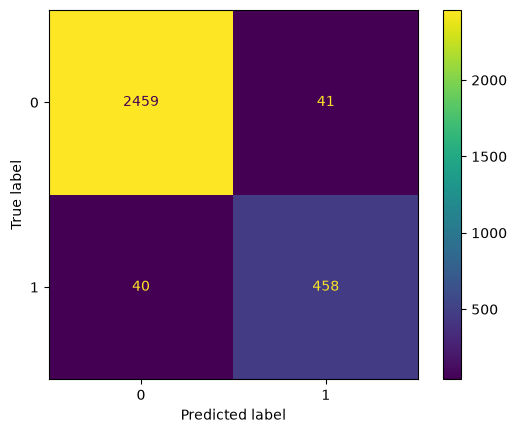

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def make_cm(model_obj, y_test):
    model = model_obj.predict(X_test)
    cm = confusion_matrix(y_test,model,labels=model_obj.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_obj.classes_)
    disp.plot()

make_cm(xgb_cv, y_test)

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

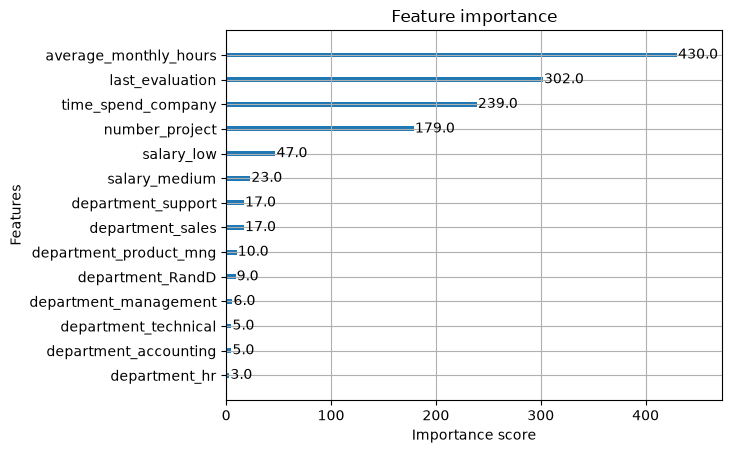

In [29]:
plot_importance(xgb_cv.best_estimator_)